In [1]:
# Sel 1: setup
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().resolve().parent))

import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from src import config as C
from src import preprocess as P
from src import dataset as D
from src import viz as V

FIG_DIR = C.AUDIT_DIR.parent / "data_prep" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def simpan(fig, nama):
    fig.savefig(FIG_DIR / f"{nama}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("IMG_SIZE:", C.IMG_SIZE, "| IGNORE_GIANT_SCAB:", C.IGNORE_GIANT_SCAB)
print("CUDA:", torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

d:\Arsip Hafizh Fadhl Muhammad\Project\skripsi\segmentasi-kentang\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


IMG_SIZE: 512 | IGNORE_GIANT_SCAB: False
CUDA: True NVIDIA GeForce RTX 3060 Laptop GPU


In [2]:
# Sel 2: buat cache 512 px (sekali saja, sekitar 5-10 menit)
manifest = pd.read_csv(C.MANIFEST_PATH)
meta = P.build_cache(manifest)
print("Citra di cache:", len(meta))
display(meta.groupby("split").size().rename("jumlah"))

cache 512px: 100%|██████████| 1627/1627 [04:53<00:00,  5.55it/s]

Citra di cache: 1627


split
test      258
train    1198
val       171
Name: jumlah, dtype: int64

In [3]:
# Sel 3: QC 1 - jumlah cache harus sama persis dengan manifest
expected = manifest[manifest["keep"]].groupby("split").size()
got = meta.groupby("split").size()
cek = pd.DataFrame({"manifest": expected, "cache": got})
cek["cocok"] = cek["manifest"] == cek["cache"]
display(cek)
assert cek["cocok"].all(), "Jumlah cache tidak sama dengan manifest"

,manifest,cache,cocok
split,,,
test,258,258,True
train,1198,1198,True
val,171,171,True


In [4]:
# Sel 4: QC 2 - adakah kelas yang hilang total setelah resize ke 512?
loss = P.class_loss_report(meta)
display(loss.pivot(index="kelas", columns="split", values="citra_kelas_hilang")[list(C.SPLITS)])

# Rasio luas setelah/sebelum letterbox, dinormalisasi skala^2 (idealnya mendekati 1)
for c, name in enumerate(C.CLASS_NAMES):
    s = meta[meta[f"px_orig_{c}"] > 0]
    ratio = s[f"px_lb_{c}"] / (s[f"px_orig_{c}"] * s["scale"] ** 2)
    print(f"{name:18s} median rasio luas = {ratio.median():.3f}")

split,train,val,test
kelas,,,
Greening,0,0,0
Mechanical Damage,0,0,0
Rot,0,0,0
Scab,0,0,0


Scab               median rasio luas = 1.000
Rot                median rasio luas = 1.000
Greening           median rasio luas = 1.000
Mechanical Damage  median rasio luas = 1.001


In [5]:
# Sel 5: QC 3 - bentuk, tipe, dan nilai satu sampel per split
for split in C.SPLITS:
    ds = D.PotatoDefectDataset(split, train=False)
    s = ds[0]
    print(f"{split:5s} n={len(ds):4d} | image {tuple(s['image'].shape)} {s['image'].dtype} "
          f"| mask {tuple(s['mask'].shape)} nilai {s['mask'].unique().tolist()}")

train n=1198 | image (3, 512, 512) torch.float32 | mask (4, 512, 512) nilai [0.0, 1.0]
val   n= 171 | image (3, 512, 512) torch.float32 | mask (4, 512, 512) nilai [0.0, 1.0]
test  n= 258 | image (3, 512, 512) torch.float32 | mask (4, 512, 512) nilai [0.0, 1.0]


In [6]:
# Sel 6: QC 4 - overlap tetap ada di mask cache (multilabel tidak hilang)
ds_train = D.PotatoDefectDataset("train", train=False)
n_overlap = 0
for i in range(len(ds_train)):
    m = ds_train[i]["mask"]
    if ((m.sum(dim=0)) >= 2).any():
        n_overlap += 1
print(f"Citra train dengan piksel berlabel ganda: {n_overlap} dari {len(ds_train)}")

Citra train dengan piksel berlabel ganda: 330 dari 1198


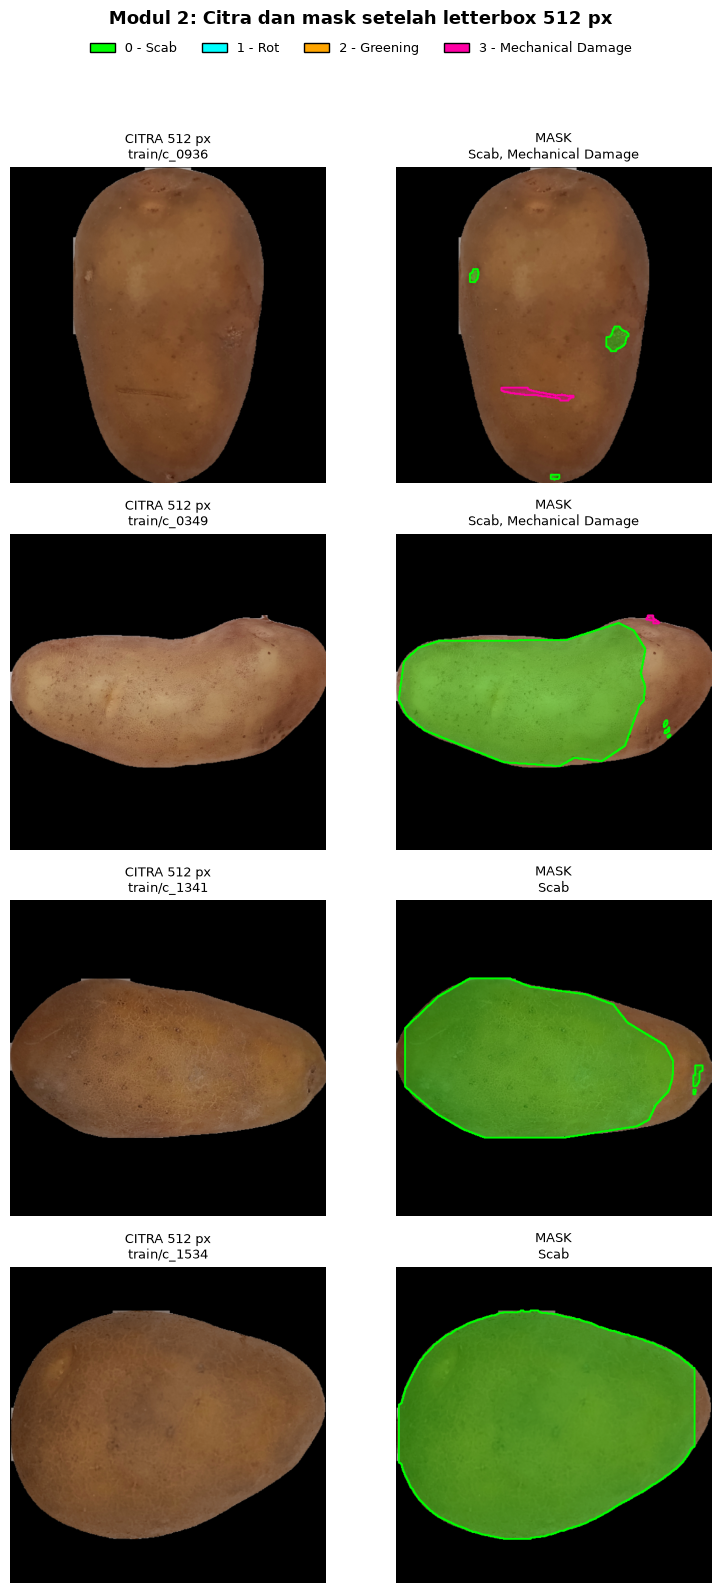

In [7]:
# Sel 7: visual 1 - citra cache (tanpa augmentasi) beserta mask
def tampilkan_sampel(ds, idxs, title):
    fig, axes = plt.subplots(len(idxs), 2, figsize=(8, 4 * len(idxs)), squeeze=False)
    for (ax_a, ax_b), i in zip(axes, idxs):
        s = ds[i]
        rgb = D.denormalize(s["image"])
        mask = s["mask"].numpy().astype(np.uint8)
        bgr = rgb[..., ::-1].copy()           # overlay() mengharapkan BGR
        ax_a.imshow(rgb)
        ax_a.set_title(f"CITRA 512 px\n{s['split']}/{s['file']}", fontsize=9)
        ax_b.imshow(V.overlay(bgr, mask))
        ax_b.set_title(f"MASK\n{V._present(mask)}", fontsize=9)
        ax_a.axis("off"); ax_b.axis("off")
    return V._finish(fig, title)

rng = np.random.default_rng(C.SEED)
idxs = rng.choice(len(ds_train), size=4, replace=False).tolist()
simpan(tampilkan_sampel(ds_train, idxs, "Modul 2: Citra dan mask setelah letterbox 512 px"),
       "m2_cache_sampel")

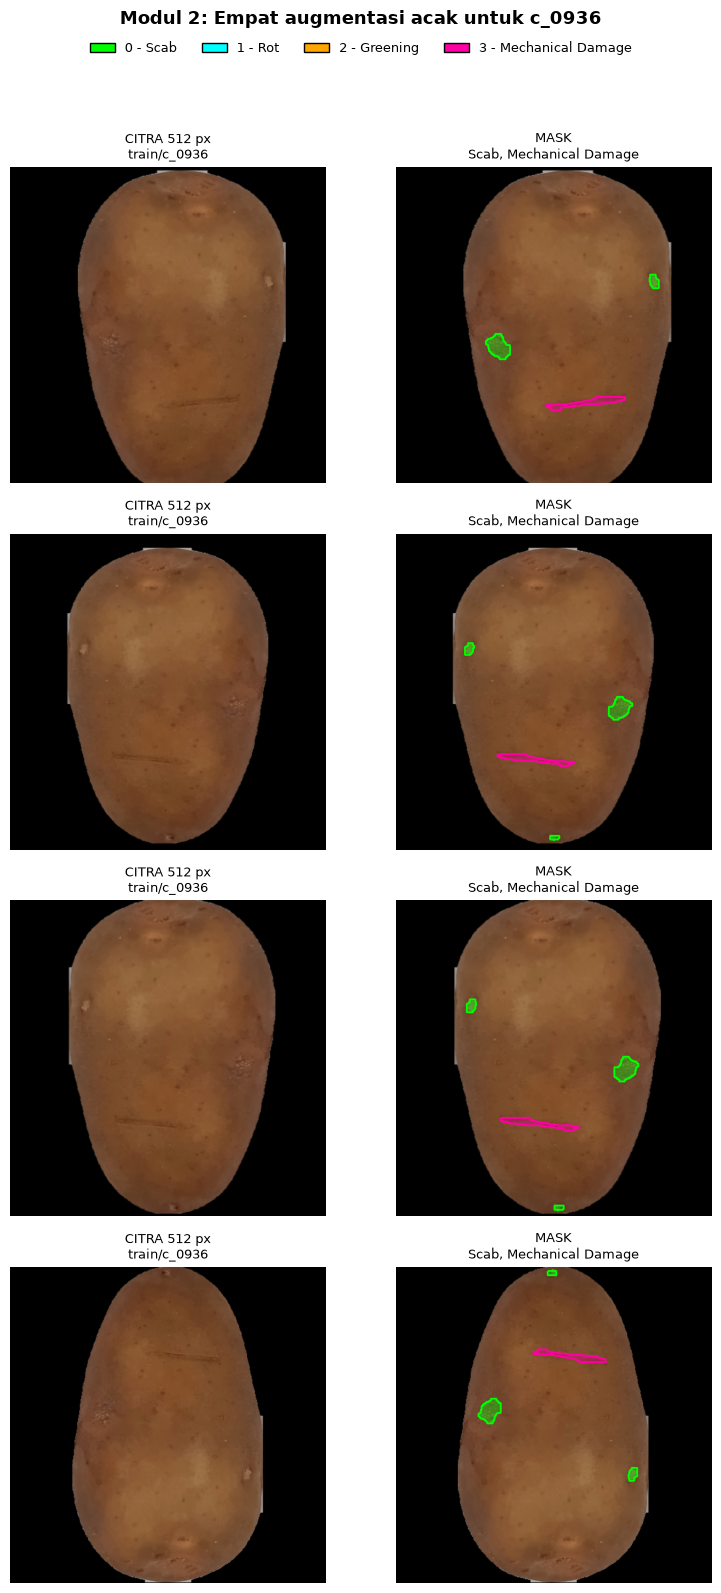

In [8]:
# Sel 8: visual 2 - augmentasi pada citra yang SAMA (mask harus ikut bergerak)
D.seed_everything()
ds_aug = D.PotatoDefectDataset("train", train=True)
i = idxs[0]
fig = tampilkan_sampel(ds_aug, [i, i, i, i],
                       f"Modul 2: Empat augmentasi acak untuk {ds_aug.files[i]}")
simpan(fig, "m2_augmentasi")

In [9]:
# Sel 9: QC 5 - DataLoader: bentuk batch dan waktu baca
D.seed_everything()
train_loader = D.build_loader(D.PotatoDefectDataset("train", train=True), shuffle=True)
val_loader = D.build_loader(D.PotatoDefectDataset("val"), shuffle=False)

t0 = time.time()
batch = next(iter(train_loader))
print("image:", tuple(batch["image"].shape), batch["image"].dtype)
print("mask :", tuple(batch["mask"].shape), batch["mask"].dtype)
print("file :", batch["file"])
print(f"Waktu 1 batch: {time.time() - t0:.2f} detik")
print("Jumlah batch train/val:", len(train_loader), len(val_loader))

image: (4, 3, 512, 512) torch.float32
mask : (4, 4, 512, 512) torch.float32
file : ['c_1522', 'c_0433', 'c_1221', 'c_0157']
Waktu 1 batch: 0.22 detik
Jumlah batch train/val: 300 43


In [10]:
# Sel 10: QC 6 - saklar IGNORE_GIANT_SCAB berfungsi (hanya untuk verifikasi)
giant_meta = meta.merge(
    pd.read_csv(C.AUDIT_DIR / "instances.csv").query("is_giant")[["split", "file"]].drop_duplicates(),
    on=["split", "file"])
ex = giant_meta[giant_meta["split"] == "train"].iloc[0]["file"]
j = ds_train.files.index(ex)
a = D.PotatoDefectDataset("train", ignore_giant_scab=False)[j]["mask"][0].sum().item()
b = D.PotatoDefectDataset("train", ignore_giant_scab=True)[j]["mask"][0].sum().item()
print(f"{ex}: piksel Scab normal = {a:.0f} | tanpa raksasa = {b:.0f}")
assert b < a

c_0073: piksel Scab normal = 132418 | tanpa raksasa = 0
